# Quantum models: The 64-Copy Problem (XXZ)

Two size-independent circuits trained to separate FM / XY / NEEL from single copies, evaluated through the organizer oracle under noise, with impostor rejection and ablations.

## 1. Setup

In [1]:
import sys, pathlib, json, time
import numpy as np
import matplotlib.pyplot as plt
import pennylane as qml

REPO = pathlib.Path.cwd()
if not (REPO / "src").exists():
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "src"))
sys.path.insert(0, str(REPO / "datasets" / "SEND_TO_PARTICIPANTS-1"))

from qphase64 import xxz as X, xxz_train as T
from qphase64.models.brickwork import Brickwork
from qphase64.models.qcnn import SharedQCNN
from oracle import CopyOracle, CopyBudgetExceeded

PHASES, BUDGET, NOISE_P = X.PHASES, 64, 0.02
KS = (1, 2, 4, 8, 16, 32, 64)
RES = REPO / "results" / "xxz"
print("results:", RES, "|", "present" if RES.exists() else "run scripts/run_xxz_quantum.py")

results: results\xxz | present


## 2. Data

In [2]:
train = X.load_public()
print(f"{len(train)} training states, {X.N_QUBITS} qubits")
for p in PHASES:
    d = train.delta[train.label == p]
    print(f"  {p:5s} n={int((train.label==p).sum()):2d}  delta in [{d.min():+.2f}, {d.max():+.2f}]")

48 training states, 16 qubits
  FM    n=14  delta in [-2.50, -1.30]
  XY    n=20  delta in [-0.70, +0.70]
  NEEL  n=14  delta in [+1.30, +2.50]


Exact phase signatures; FM is fully polarized, NEEL is staggered.

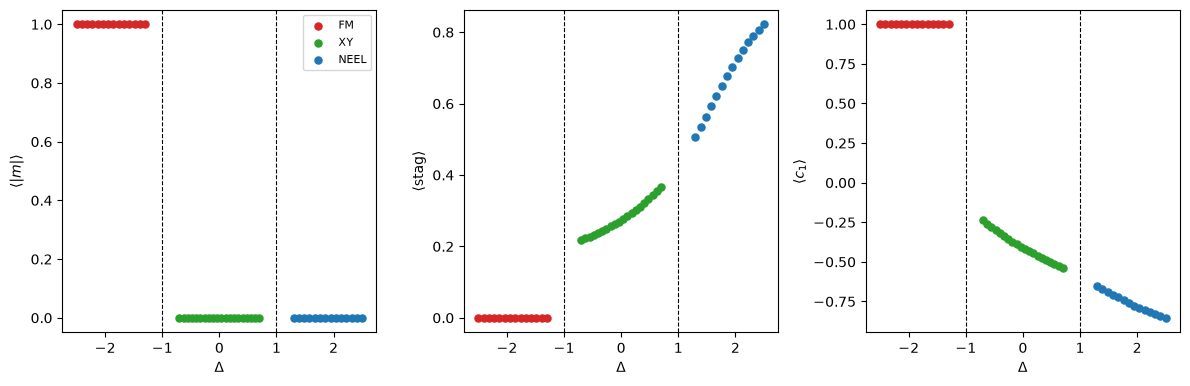

In [3]:
tab = X.basis_tables()
sig = []
for k in range(len(train)):
    p = train.psi[k] ** 2; p /= p.sum()
    sig.append([train.delta[k]] + [float(p @ tab[s]) for s in ("m_abs", "stag", "c1")])
sig = np.array(sig)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.964))
for ax, j, nm in zip(axes, (1, 2, 3), (r"$\langle|m|\rangle$", r"$\langle$stag$\rangle$", r"$\langle c_1\rangle$")):
    for p, c in zip(PHASES, ["tab:red", "tab:green", "tab:blue"]):
        m = train.label == p
        ax.scatter(sig[m, 0], sig[m, j], s=26, color=c, label=p)
    for b in (-1, 1): ax.axvline(b, color="k", ls="--", lw=0.8)
    ax.set_xlabel(r"$\Delta$"); ax.set_ylabel(nm)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 3. The two circuits

Both reuse one small gate at many places, so the parameter count does not depend on the number of qubits.

In [4]:
m1 = Brickwork(n_qubits=X.N_QUBITS, layers=2, kernel="z2", single="rx", periodic=True)
m2 = SharedQCNN(n_qubits=X.N_QUBITS, kernel="z2", pool="z2pool", n_out=2, periodic=True)

print(f"{'N':>4} {'brickwork':>11} {'QCNN tied':>11} {'QCNN untied':>12} {'QCNN rounds':>12}")
for n in (4, 8, 12, 16, 24):
    print(f"{n:>4} {Brickwork(n, layers=2, periodic=True).n_params():>11}"
          f" {SharedQCNN(n, periodic=True).n_params():>11}"
          f" {SharedQCNN(n, tied=False, periodic=True).n_params():>12}"
          f" {SharedQCNN(n, periodic=True).n_levels():>12}")
print("\nthe tied columns are flat; the untied one grows and could not transfer")

   N   brickwork   QCNN tied  QCNN untied  QCNN rounds
   4          16          18           18            1
   8          16          18           29            2
  12          16          18           40            3
  16          16          18           40            3
  24          16          18           51            4

the tied columns are flat; the untied one grows and could not transfer


Brickwork: the same two-qubit gate at every bond, two layers.

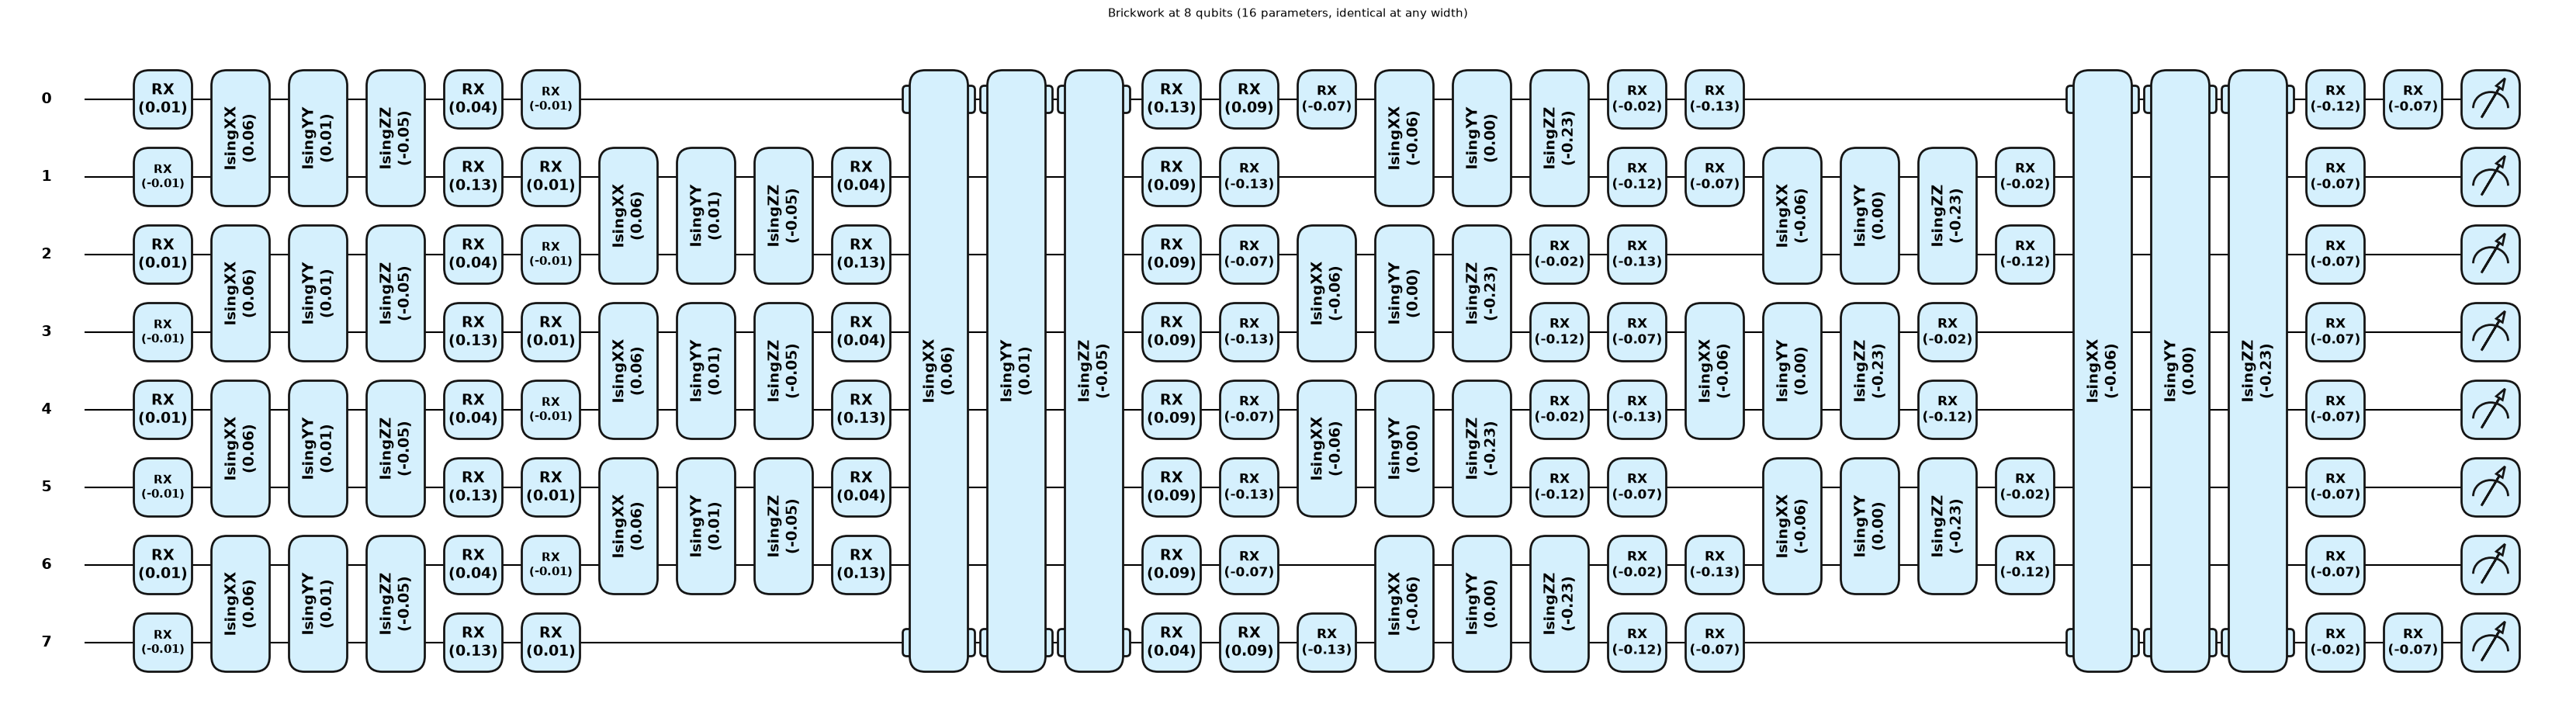

In [5]:
def draw(model, n, title):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev)
    def circ(theta):
        model.apply(theta)
        return qml.probs(wires=range(n))
    fig, ax = qml.draw_mpl(circ, style="pennylane", decimals=2)(model.init_params(0))
    fig.suptitle(title, y=1.02, fontsize=11)
    plt.show()

draw(Brickwork(8, layers=2, kernel="z2", single="rx", periodic=True), 8,
     "Brickwork at 8 qubits (16 parameters, identical at any width)")

QCNN: convolve, drop half the wires, repeat; all rounds share parameters.

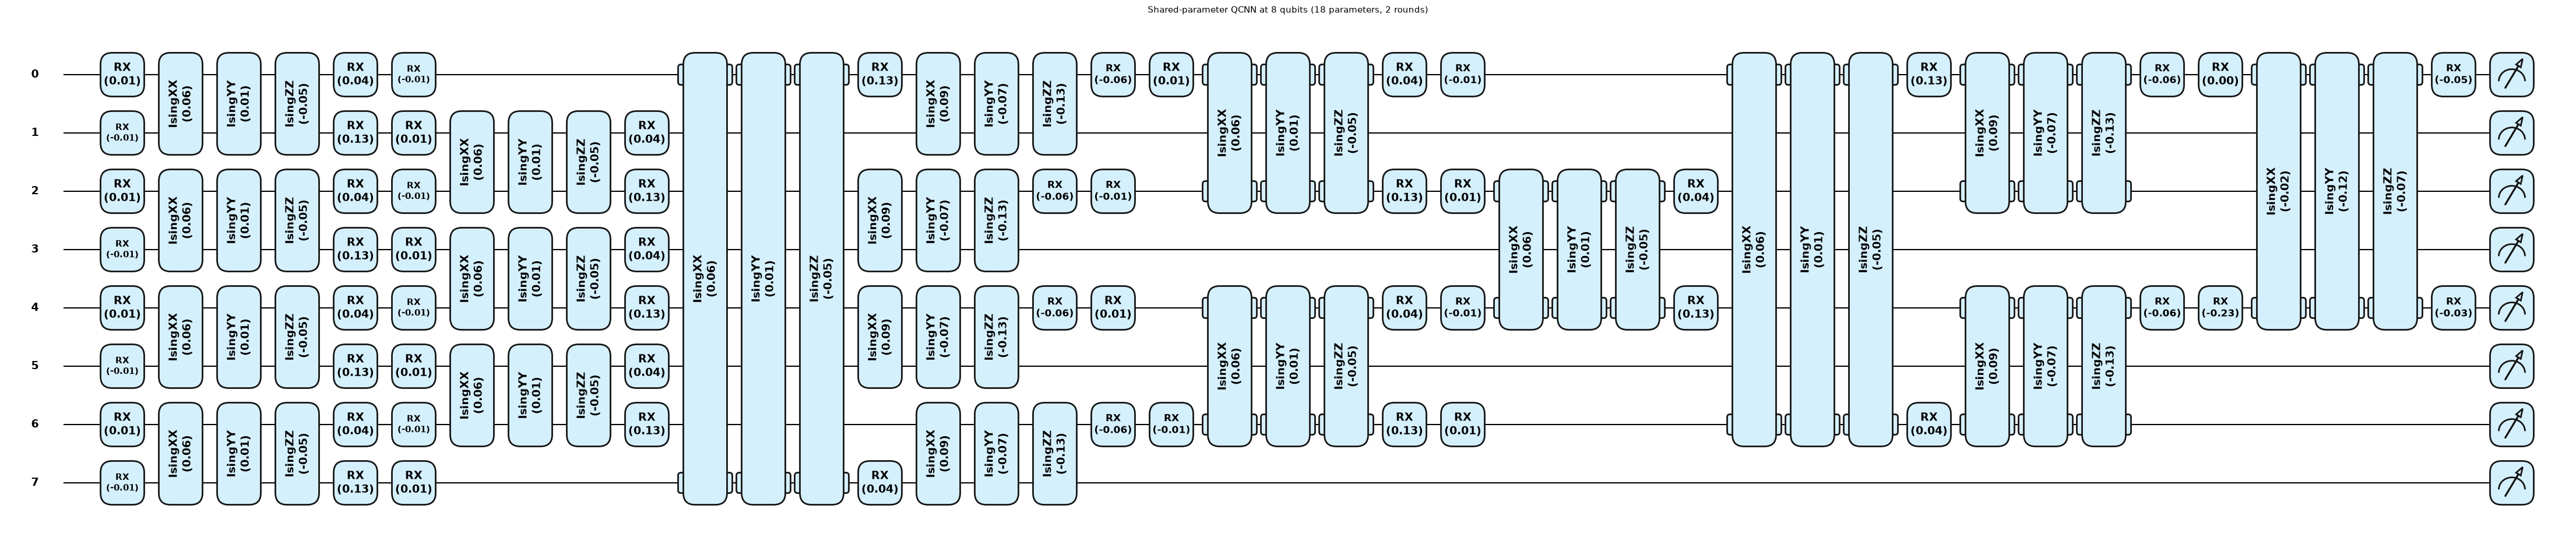

wire schedule at 16 qubits:
  round 0  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
  round 1  [0, 2, 4, 6, 8, 10, 12, 14]
  round 2  [0, 4, 8, 12]
  output   [0, 8]


In [6]:
draw(SharedQCNN(8, kernel="z2", pool="z2pool", n_out=2, periodic=True), 8,
     "Shared-parameter QCNN at 8 qubits (18 parameters, 2 rounds)")

q16 = SharedQCNN(16, periodic=True)
print("wire schedule at 16 qubits:")
for i, lv in enumerate(q16.levels()):
    print(f"  {'output' if i == q16.n_levels() else f'round {i}':8s} {lv}")

## 4. The oracle

In [7]:
o = CopyOracle(str(X.TRAIN_NPZ), copy_budget=BUDGET, noise_p=NOISE_P, seed=0)
ops = X.make_ops_fn(m1, m1.init_params(0))

print("one metered copy through the brickwork:", o.measure("T00", ops_fn=ops))
for _ in range(63): o.measure("T00", ops_fn=ops)
try:
    o.measure("T00", ops_fn=ops)
except CopyBudgetExceeded as e:
    print("copy 65 refused:", e)

one metered copy through the brickwork: [0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0]


copy 65 refused: copy budget (64) exhausted for T00


## 5. Noise

Depolarizing applies X, Y or Z with probability p/3; X and Y flip a computational-basis bit and Z does not, so the outcome channel is a bit flip at 2p/3.

In [8]:
k = int(np.where(train.label == "NEEL")[0][5])
print(f"{'p':>6} {'predicted':>10} {'oracle':>8}")
for p_noise in (0.0, 0.02, 0.05, 0.10):
    pv = train.psi[k] ** 2; pv /= pv.sum()
    pred = X.bitflip_channel(pv, X.flip_rate(p_noise)) @ tab["m_abs"]
    oc = CopyOracle(str(X.TRAIN_NPZ), copy_budget=BUDGET, noise_p=p_noise, seed=3)
    emp = X.readout_matrix(np.stack([oc.measure(train.ids[k]) for _ in range(64)]),
                           ("m_abs",))[:, 0].mean()
    print(f"{p_noise:6.2f} {pred:10.3f} {emp:8.3f}")

     p  predicted   oracle


  0.00      0.000    0.000


  0.02      0.024    0.021


  0.05      0.052    0.045


  0.10      0.086    0.092


## 6. Training

In [9]:
t0 = time.time()
res1 = T.train(m1, train, noise_p=NOISE_P, steps=120, seed=0, eval_every=40, verbose=True)
print(f"brickwork trained in {res1.seconds:.0f}s")
res2 = T.train(m2, train, noise_p=NOISE_P, steps=120, seed=0,
               out_wires=tuple(m2.output_wires()), eval_every=40, verbose=True)
print(f"QCNN trained in {res2.seconds:.0f}s")
print("\nQCNN symbol table P(symbol | phase):")
print("        " + "  ".join(f"{b:>6}" for b in ("00", "01", "10", "11")))
for i, p in enumerate(PHASES):
    print(f"  {p:5s} " + "  ".join(f"{v:6.3f}" for v in res2.likelihood.table[i]))

    step    0  loss -0.2888  (3s)


    step   40  loss -0.2676  (67s)


    step   80  loss -0.2343  (138s)


    step  119  loss -0.1589  (206s)


brickwork trained in 210s


    step    0  loss -0.0167  (2s)


    step   40  loss -0.0407  (70s)


    step   80  loss -0.0480  (136s)


    step  119  loss -0.0214  (241s)


QCNN trained in 246s

QCNN symbol table P(symbol | phase):
            00      01      10      11
  FM     0.925   0.015   0.015   0.045
  XY     0.250   0.250   0.250   0.250
  NEEL   0.397   0.103   0.103   0.397


## 7. Accuracy against copies

In [10]:
near = X.near_boundary(n_per_side=24, width=0.28)
print(f"{len(near)} near-boundary states, |delta| in "
      f"[{np.abs(near.delta).min():.2f}, {np.abs(near.delta).max():.2f}]")

def curve(model, theta, lik, data, seed=0, noise_p=NOISE_P):
    rng = np.random.default_rng(seed)
    shots = X.sample_batch(data.psi, model, theta, BUDGET, noise_p, rng)
    return {k: float(np.mean([PHASES[lik.predict(s[:k])] for s in shots] == data.label))
            for k in KS}, shots

c1_tr, _ = curve(m1, res1.theta, res1.likelihood, train)
c2_tr, _ = curve(m2, res2.theta, res2.likelihood, train)
c1_nb, sh1 = curve(m1, res1.theta, res1.likelihood, near)
c2_nb, _ = curve(m2, res2.theta, res2.likelihood, near)

print(f"\n{'':22s}" + "".join(f"{('k='+str(k)):>8}" for k in KS))
for nm, c in (("brickwork train", c1_tr), ("brickwork near-bdy", c1_nb),
              ("QCNN train", c2_tr), ("QCNN near-bdy", c2_nb)):
    print(f"{nm:22s}" + "".join(f"{c[k]:8.3f}" for k in KS))

48 near-boundary states, |delta| in [0.72, 1.28]



                           k=1     k=2     k=4     k=8    k=16    k=32    k=64
brickwork train          0.750   0.854   0.833   0.938   0.917   0.958   0.958
brickwork near-bdy       0.812   0.854   0.792   0.833   0.812   0.812   0.854
QCNN train               0.542   0.708   0.729   0.875   0.896   0.917   0.958
QCNN near-bdy            0.500   0.667   0.688   0.792   0.833   0.771   0.792


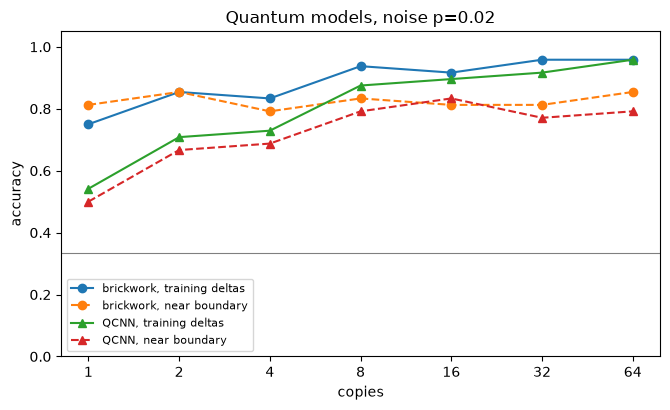

In [11]:
fig, ax = plt.subplots(figsize=(6.8, 4.2))
for nm, c, st in (("brickwork, training deltas", c1_tr, "o-"),
                  ("brickwork, near boundary", c1_nb, "o--"),
                  ("QCNN, training deltas", c2_tr, "^-"),
                  ("QCNN, near boundary", c2_nb, "^--")):
    ax.plot(list(c), list(c.values()), st, label=nm)
ax.axhline(1/3, color="k", lw=0.8, alpha=0.5)
ax.set_xscale("log", base=2); ax.set_xticks(KS); ax.set_xticklabels(KS)
ax.set_xlabel("copies"); ax.set_ylabel("accuracy"); ax.set_ylim(0, 1.05)
ax.set_title(f"Quantum models, noise p={NOISE_P}")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 8. Confusion at 16 copies

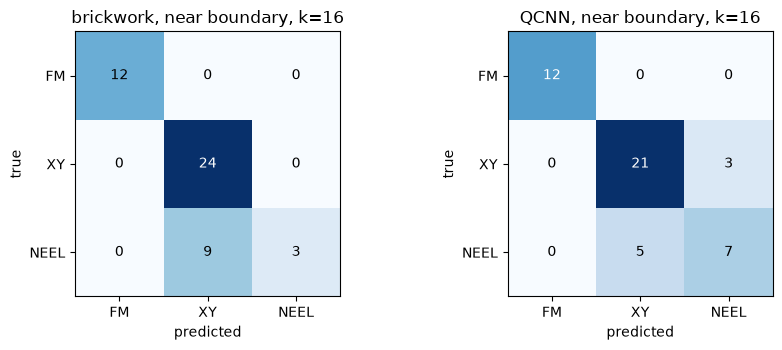

In [12]:
from collections import Counter
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (nm, model, r, data, shots) in zip(axes, [
        ("brickwork", m1, res1, near, sh1),
        ("QCNN", m2, res2, near, X.sample_batch(near.psi, m2, res2.theta, BUDGET,
                                                NOISE_P, np.random.default_rng(0)))]):
    M = np.zeros((3, 3), int)
    for s, t in zip(shots, data.label):
        M[PHASES.index(t), r.likelihood.predict(s[:16])] += 1
    ax.imshow(M, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, M[i, j], ha="center", va="center",
                    color="white" if M[i, j] > M.max() / 2 else "black")
    ax.set_xticks(range(3), PHASES); ax.set_yticks(range(3), PHASES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{nm}, near boundary, k=16")
plt.tight_layout(); plt.show()

## 9. Noise robustness

In [13]:
rows = {}
for nm, model, r, ow in (("brickwork", m1, res1, None),
                         ("QCNN", m2, res2, tuple(m2.output_wires()))):
    for aware in (True, False):
        lik = r.likelihood if aware else T.fit_at(model, train, r.theta, 0.0, out_wires=ow)
        rows[(nm, aware)] = {}
        for p_noise in (0.0, 0.02, 0.05, 0.10):
            a, _ = curve(model, r.theta, lik, near, noise_p=p_noise)
            rows[(nm, aware)][p_noise] = a[16]

print(f"{'model':10s} {'noise-aware':>12s} " + "".join(f"{('p='+str(p)):>9}" for p in (0.0,0.02,0.05,0.10)))
for (nm, aware), v in rows.items():
    print(f"{nm:10s} {str(aware):>12s} " + "".join(f"{v[p]:9.3f}" for p in (0.0,0.02,0.05,0.10)))

model       noise-aware     p=0.0   p=0.02   p=0.05    p=0.1
brickwork          True     0.833    0.812    0.854    0.792
brickwork         False     0.812    0.812    0.854    0.792
QCNN               True     0.812    0.833    0.729    0.729
QCNN              False     0.812    0.812    0.708    0.688


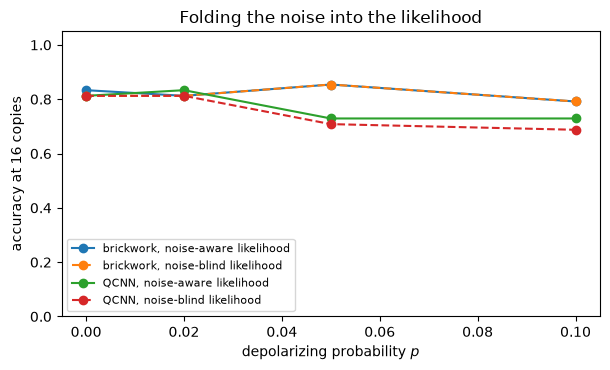

In [14]:
fig, ax = plt.subplots(figsize=(6.2, 3.8))
for (nm, aware), v in rows.items():
    ax.plot(list(v), list(v.values()), "o-" if aware else "o--",
            label=f"{nm}, {'noise-aware' if aware else 'noise-blind'} likelihood")
ax.set_xlabel("depolarizing probability $p$"); ax.set_ylabel("accuracy at 16 copies")
ax.set_ylim(0, 1.05); ax.legend(fontsize=8)
ax.set_title("Folding the noise into the likelihood")
plt.tight_layout(); plt.show()

## 10. Impostors

Jordan-Wigner puts the two spin species of one site on wires (2i, 2i+1); for XXZ every wire is an equivalent chain site, so `pair - c1` is zero by symmetry.

In [15]:
fh = X.impostors(n_states=25)
rng = np.random.default_rng(0)

def gap(psi, k=32, noise_p=NOISE_P):
    pr = X.bitflip_channel(np.abs(psi) ** 2, X.flip_rate(noise_p))
    d = rng.choice(len(pr), size=k, p=np.clip(pr, 0, None) / pr.sum())
    return float(np.mean(tab["pair"][d] - tab["c1"][d]))

g_train = np.array([gap(p) for p in train.psi])
g_near  = np.array([gap(p) for p in near.psi])
g_fh    = np.array([gap(p) for p in fh])
thr = np.percentile(np.concatenate([g_train, g_near]), 1.0) - 0.02

print(f"XXZ      pair-c1  mean {np.concatenate([g_train,g_near]).mean():+.3f}")
print(f"impostor pair-c1  mean {g_fh.mean():+.3f}")
print(f"threshold {thr:+.3f} -> recall {np.mean(g_fh < thr):.3f}, "
      f"false rejects {np.mean(np.concatenate([g_train,g_near]) < thr):.3f}")

XXZ      pair-c1  mean +0.002
impostor pair-c1  mean -0.265
threshold -0.106 -> recall 1.000, false rejects 0.000


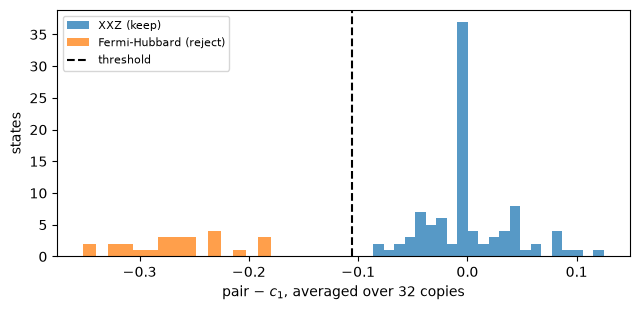

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.hist(np.concatenate([g_train, g_near]), bins=22, alpha=0.75, label="XXZ (keep)")
ax.hist(g_fh, bins=15, alpha=0.75, label="Fermi-Hubbard (reject)")
ax.axvline(thr, color="k", ls="--", label="threshold")
ax.set_xlabel(r"pair $-$ $c_1$, averaged over 32 copies"); ax.set_ylabel("states")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 11. Copy accounting

In [17]:
oc = CopyOracle(str(X.TRAIN_NPZ), copy_budget=BUDGET, noise_p=NOISE_P, seed=5)
ops = X.make_ops_fn(m1, res1.theta)
K_USE = 32
preds = []
for sid in train.ids:
    shots = np.stack([oc.measure(sid, ops_fn=ops) for _ in range(K_USE)])
    preds.append(PHASES[res1.likelihood.predict(shots)])
u = np.array(list(oc.usage_report().values()))
print(f"oracle accuracy {np.mean(np.array(preds) == train.label):.3f}")
print(f"copies: mean {u.mean():.1f}, max {u.max()} of {BUDGET}")
assert u.max() <= BUDGET
print("within budget on every state")

oracle accuracy 0.979
copies: mean 32.0, max 32 of 64
within budget on every state


## 12. Full-run results

In [18]:
def load(name):
    p = RES / f"{name}.json"
    return json.loads(p.read_text()) if p.exists() else None

head, abl, noi, imp = load("headline"), load("ablations"), load("noise"), load("impostor")
if head:
    print(f"{'model':10s} {'params':>7s} " + "".join(f"{('k='+str(k)):>8}" for k in KS))
    for nm in ("M1", "M2"):
        if nm not in head: continue
        runs = head[nm]
        for split in ("train_deltas", "near_boundary"):
            v = {k: np.mean([r[split][str(k)] for r in runs]) for k in KS}
            s = {k: np.std([r[split][str(k)] for r in runs]) for k in KS}
            print(f"{nm+' '+split[:9]:20s} {runs[0]['params']:>4} "
                  + "".join(f"{v[k]:8.3f}" for k in KS))
        if nm + "_oracle" in head:
            print(f"   oracle: {head[nm+'_oracle']}")
else:
    print("run scripts/run_xxz_quantum.py --seeds 0 1 2 first")

model       params      k=1     k=2     k=4     k=8    k=16    k=32    k=64
M1 train_del           16    0.764   0.882   0.958   0.958   0.965   0.986   1.000
M1 near_boun           16    0.653   0.729   0.785   0.799   0.861   0.854   0.910
   oracle: {'accuracy': 1.0, 'usage': {'mean': 32.0, 'max': 32}}
M2 train_del           18    0.625   0.757   0.840   0.882   0.931   0.958   0.972
M2 near_boun           18    0.507   0.618   0.646   0.736   0.785   0.785   0.792
   oracle: {'accuracy': 0.9166666666666666, 'usage': {'mean': 32.0, 'max': 32}}


In [19]:
if abl:
    print(f"{'group':12s} {'config':14s} {'par':>4s} {'flat':>5s} "
          f"{'near k4':>8s} {'k16':>7s} {'k64':>7s}")
    for r in abl:
        if "error" in r:
            print(f"{r['group']:12s} {r['config']:14s}  FAILED {r['error'][:40]}"); continue
        print(f"{r['group']:12s} {r['config']:14s} {r['params']:>4} "
              f"{str(r['size_independent']):>5} {r['near_k4']:8.3f} "
              f"{r['near_k16']:7.3f} {r['near_k64']:7.3f}")

group        config          par  flat  near k4     k16     k64
M1 depth     L=1               8  True    0.750   0.833   0.833
M1 depth     L=2              16  True    0.792   0.812   0.854
M1 depth     L=3              24  True    0.771   0.812   0.812
M1 kernel    general (9)      20 False    0.750   0.812   0.792
M1 readout   m_abs only       16  True    0.750   0.750   0.750
M1 readout   m_abs+stag       16  True    0.792   0.812   0.854
M1 readout   +c1             FAILED operands could not be broadcast together
M1 loss      C1               16  True    0.729   0.667   0.667
M1 loss      C2               16  True    0.792   0.812   0.854
M2 n_out     1                14  True    0.688   0.667   0.750
M2 n_out     2                18  True    0.750   0.896   0.833
M2 tying     untied           40 False    0.667   0.750   0.854


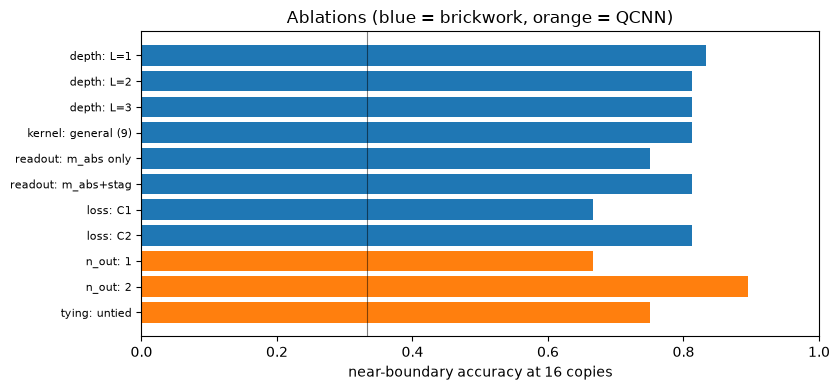

In [20]:
if abl:
    rows = [r for r in abl if "error" not in r]
    fig, ax = plt.subplots(figsize=(8.5, 4))
    lbl = [f"{r['group'].replace('M1 ','').replace('M2 ','')}: {r['config']}" for r in rows]
    y = np.arange(len(rows))
    ax.barh(y, [r["near_k16"] for r in rows], color=["tab:blue" if r["group"].startswith("M1")
                                                     else "tab:orange" for r in rows])
    ax.set_yticks(y, lbl, fontsize=8); ax.invert_yaxis()
    ax.axvline(1/3, color="k", lw=0.8, alpha=0.5)
    ax.set_xlabel("near-boundary accuracy at 16 copies"); ax.set_xlim(0, 1)
    ax.set_title("Ablations (blue = brickwork, orange = QCNN)")
    plt.tight_layout(); plt.show()

## 13. Training objective

The Chernoff exponent is the asymptotic decay rate of the error; the fixed-k surrogate targets accuracy at a chosen copy count instead.

objective                              k=1     k=2     k=4     k=8    k=16    k=32    k=64
Chernoff exponent (asymptotic)       0.688   0.854   0.792   0.917   0.854   0.833   0.917
fixed-k surrogate (k=8)              0.625   0.708   0.792   0.833   0.833   0.896   0.938


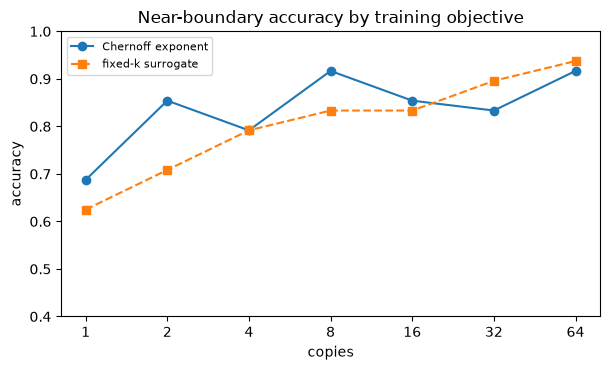

In [21]:
ls = load("loss_study")
if ls:
    print(f"{'objective':34s}" + "".join(f"{('k='+str(k)):>8}" for k in KS))
    for nm, lab in (("C2", "Chernoff exponent (asymptotic)"),
                    ("C3", "fixed-k surrogate (k=8)")):
        print(f"{lab:34s}" + "".join(f"{ls[nm][str(k)]:8.3f}" for k in KS))

    fig, ax = plt.subplots(figsize=(6.2, 3.8))
    for nm, lab, st in (("C2", "Chernoff exponent", "o-"),
                        ("C3", "fixed-k surrogate", "s--")):
        ax.plot(KS, [ls[nm][str(k)] for k in KS], st, label=lab)
    ax.axhline(1/3, color="k", lw=0.8, alpha=0.5)
    ax.set_xscale("log", base=2); ax.set_xticks(KS); ax.set_xticklabels(KS)
    ax.set_xlabel("copies"); ax.set_ylabel("accuracy"); ax.set_ylim(0.4, 1.0)
    ax.set_title("Near-boundary accuracy by training objective")
    ax.legend(fontsize=8); plt.tight_layout(); plt.show()
else:
    print("run scripts/build_xxz_submission.py")

## 14. Saved model

The checkpoint holds theta and the fitted tables, so the trained circuit can be reloaded and submitted.

In [22]:
ckpt = REPO / "models" / "xxz_brickwork.npz"
if ckpt.exists():
    model_s, theta_s, lik_s, meta_s = X.load_model(ckpt)
    print(f"model      {meta_s['model']} {meta_s['model_kwargs']}")
    print(f"parameters {len(theta_s)}  ({np.round(theta_s, 3)})")
    print(f"features   {meta_s['features']}   noise_p {meta_s['noise_p']}")
    print(f"tables     P(symbol|phase) {lik_s.table.shape}")
    c = curve(model_s, theta_s, lik_s, near)[0]
    print("\nnear-boundary from the reloaded checkpoint:")
    print("  " + "  ".join(f"k={k}:{c[k]:.3f}" for k in (4, 8, 16, 64)))
else:
    print("run scripts/build_xxz_submission.py")

model      brickwork {'layers': 2, 'kernel': 'z2', 'single': 'rx', 'periodic': True}
parameters 16  ([ 0.01  -0.04  -0.099  0.119 -0.013  0.017  0.067  0.058 -0.086 -0.073
  0.439 -0.461  0.001  0.02   0.009  0.024])
features   ['m_abs', 'stag']   noise_p 0.02
tables     P(symbol|phase) (3, 25)



near-boundary from the reloaded checkpoint:
  k=4:0.792  k=8:0.917  k=16:0.854  k=64:0.917


## 15. Mixed validation set

Near-boundary XXZ plus Fermi-Hubbard impostors, scored by the organizer's own `evaluate.py` through the metered oracle.

In [23]:
import subprocess
KIT = REPO / "datasets" / "SEND_TO_PARTICIPANTS-1"
mixed = RES / "mixed_validation.npz"
key = RES / "mixed_validation.key.csv"

if mixed.exists():
    for sub in ("submission.py", "submission_quantum.py"):
        path = REPO / sub
        if not path.exists():
            continue
        print("=" * 62); print(sub); print("=" * 62)
        r = subprocess.run([sys.executable, str(KIT / "evaluate.py"), str(path),
                            "--data", str(mixed), "--key", str(key),
                            "--noise_p", "0.02", "--budget", "64"],
                           cwd=str(KIT), capture_output=True, text=True)
        print(r.stdout[-1500:] if r.returncode == 0 else r.stderr[-700:])
else:
    print("run scripts/build_xxz_submission.py")

submission.py



--- per-class metrics (XXZ states only) ---
FM     P=1.000  R=1.000  F1=1.000
XY     P=0.821  R=0.958  F1=0.885
NEEL   P=0.857  R=0.500  F1=0.632
MACRO-F1 (headline metric): 0.839

impostor detection: P=0.962  R=1.000

--- accuracy by tier ---
impostor  25/25 = 1.00
near_boundary 41/48 = 0.85

--- copy usage ---
mean 32.0, min 32, max 32 of 64

--- confusion (truth -> pred) ---
truth\pred       FM       XY     NEEL  UNKNOWN  MISSING
FM               12        0        0        0        0
XY                0       23        1        0        0
NEEL              0        5        6        1        0
IMPOSTOR          0        0        0       25        0

submission_quantum.py



--- per-class metrics (XXZ states only) ---
FM     P=1.000  R=1.000  F1=1.000
XY     P=0.833  R=0.833  F1=0.833
NEEL   P=0.833  R=0.417  F1=0.556
MACRO-F1 (headline metric): 0.796

impostor detection: P=0.774  R=0.960

--- accuracy by tier ---
impostor  24/25 = 0.96
near_boundary 37/48 = 0.77

--- copy usage ---
mean 31.0, min 8, max 48 of 64

--- confusion (truth -> pred) ---
truth\pred       FM       XY     NEEL  UNKNOWN  MISSING
FM               12        0        0        0        0
XY                0       20        1        3        0
NEEL              0        3        5        4        0
IMPOSTOR          0        1        0       24        0



In [24]:
head = load("headline")
if head:
    print("near-boundary accuracy, mean over seeds\n")
    print(f"{'protocol':28s}" + "".join(f"{('k='+str(k)):>8}" for k in KS))
    for nm, lab in (("M1", "brickwork (16 params)"), ("M2", "QCNN (18 params)")):
        runs = head[nm]
        v = [np.mean([r["near_boundary"][str(k)] for r in runs]) for k in KS]
        print(f"{lab:28s}" + "".join(f"{x:8.3f}" for x in v))
    print(f"{'classical order parameter':28s}" +
          "".join(f"{x:8.3f}" for x in (np.nan, np.nan, 0.857, 0.821, 0.857, 0.857, 0.857)))
    print("\noracle, training states:",
          {k: head[k] for k in head if k.endswith("_oracle")})

near-boundary accuracy, mean over seeds

protocol                         k=1     k=2     k=4     k=8    k=16    k=32    k=64
brickwork (16 params)          0.653   0.729   0.785   0.799   0.861   0.854   0.910
QCNN (18 params)               0.507   0.618   0.646   0.736   0.785   0.785   0.792
classical order parameter        nan     nan   0.857   0.821   0.857   0.857   0.857

oracle, training states: {'M1_oracle': {'accuracy': 1.0, 'usage': {'mean': 32.0, 'max': 32}}, 'M2_oracle': {'accuracy': 0.9166666666666666, 'usage': {'mean': 32.0, 'max': 32}}}
